In [1]:
import torch
import matplotlib.pyplot as plt
import torch.nn.functional as F

In [2]:
words = open('names.txt', 'r').read().splitlines()

In [3]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}

In [4]:
# create the training set of bigrams (x,y)
xs, ys = [], []

for w in words[:1]:
  chs = ['.'] + list(w) + ['.']
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = stoi[ch1]
    ix2 = stoi[ch2]
    print(ch1, ch2)
    xs.append(ix1)
    ys.append(ix2)
    
xs = torch.tensor(xs)
ys = torch.tensor(ys)

. e
e m
m m
m a
a .


In [5]:
# randomly initialize 27 neurons' weights. each neuron receives 27 inputs
g = torch.Generator().manual_seed(2147483647)
W1 = torch.randn((27, 27), generator=g)

In [6]:
xenc = F.one_hot(xs, num_classes=27).float() # input to the network: one-hot encoding
logits = xenc @ W1 # predict log-counts
counts = logits.exp() # counts, equivalent to N
probs = counts / counts.sum(1, keepdims=True) # probabilities for next character
# btw: the last 2 lines here are together called a 'softmax'

In [7]:
probs.shape

torch.Size([5, 27])

In [8]:
xs

tensor([ 0,  5, 13, 13,  1])

In [9]:
ys

tensor([ 5, 13, 13,  1,  0])

In [10]:
import time

In [11]:
# create the dataset
xs, ys = [], []
for w in words[:1]:
  chs = ['.'] + list(w) + ['.']
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = stoi[ch1]
    ix2 = stoi[ch2]
    xs.append(ix1)
    ys.append(ix2)
xs = torch.tensor(xs)
ys = torch.tensor(ys)
num = xs.nelement()
print('number of examples: ', num)

# initialize the 'network'
g = torch.Generator().manual_seed(2147483647)
W1 = torch.randn((27, 27), generator=g, requires_grad=True)

W1_clone = W1.clone()
W1_grad_clone = None

arr = []
arr_losses = []
arr_main_loss = []
arr_synthetic_loss = []
arr_test_loss = []

z = torch.ones(W1[xs].view(-1).shape[0], 2)

# second layer
W2 = torch.randn((27, 500), generator=g, requires_grad=True)
W3 = torch.randn((500, 100), generator=g, requires_grad=True)
W4 = torch.randn((100, 27), generator=g, requires_grad=True)
act = torch.nn.ReLU()

build_2d_plot_flag = 0

# optimizer - settings from makemore
#params = {W1, W2, W3, W4}
params = {W1}
print("number of layers: " , len(params))
optimizer = torch.optim.SGD(params, lr=0.1, momentum=0.9)
#optimizer = torch.optim.AdamW(params, lr=5e-4, weight_decay=0.01, betas=(0.9, 0.99), eps=1e-8)
#optimizer = torch.optim.AdamW(params, lr=0.1, weight_decay=0.01, betas=(0.9, 0.99), eps=1e-8)

print()
print( "--- parameters in layers --- ")
total_sum = 0
for p in params:
    print(p.view(-1).shape)
    total_sum += p.view(-1).shape[0]
print(20*'-')
print( "TOTAL: ", total_sum)
print(20*'-')

number of examples:  5
number of layers:  1

--- parameters in layers --- 
torch.Size([729])
--------------------
TOTAL:  729
--------------------


In [12]:
xs, ys

(tensor([ 0,  5, 13, 13,  1]), tensor([ 5, 13, 13,  1,  0]))

In [13]:
words[:3]

['emma', 'olivia', 'ava']

In [14]:
# gradient descent
start_timer = time.perf_counter()
for k in range(50):
    
    # forward pass
    xenc = F.one_hot(xs, num_classes=27).float() # input to the network: one-hot encoding
    #print(xenc)
    logits = xenc @ W1 # predict log-counts
    #logits = act(logits)
    #logits = logits @ W1
    #l1 = torch.tanh(logits)
    #l2 = torch.tanh(logits @ W2) @ W3
    #print(l2)
    #break
    #l3 = l2 @ W3
    #logits = torch.tanh(l2) @ W4
    #print(logits.shape)
    #print(logits)
    #break

    """
    # num samples = 1, 2, 3 - most of tests for this is for for w in words[:1]: -> emma\n
    if num < 20:
        # compute expensive - MEMORY!!!
        index = 0
        for i in W1[xs].view(-1)[:]:
            #print(i)
            #print(z[index] * i )
            z[index] *= i
            index += 1
        arr.append(z.clone())
        # check flag
        if build_2d_plot_flag == 0:
            print(" 2d plot builder active")
            build_2d_plot_flag = 1
    """
    
    counts = logits.exp() # counts, equivalent to N
    probs = counts / counts.sum(1, keepdims=True) # probabilities for next character
    #print(probs)
    #print(-probs[torch.arange(num), ys].log())

    arr_losses.append(-probs[torch.arange(num), ys].log().detach().numpy())
    
    #loss = -probs[torch.arange(num), ys].log().mean() + 0.01*(W1**2).mean()

    loss = -probs[torch.arange(num), ys].log().mean() # I NEED RAW .mean() only

    #arr_main_loss.append(loss.item()) # collect before BACKWARD(). call
    #arr_synthetic_loss.append(torch.tensor(arr_losses).mean().item())

    #test_loss = F.cross_entropy(logits, ys)
    #arr_test_loss.append(test_loss.item())
    
    #print(-probs[torch.arange(num), ys].log())
    
    print(k , loss.item())
    
    # backward pass
    #W1.grad = None # set to zero the gradient
    #W2.grad = None 

    optimizer.zero_grad()
    
    loss.backward()

    if (k == 0):
        W1_grad_clone = W1.grad.clone()

    #break
    
    # LR form 50 to 1
    LR = 1
    # update
    #W1.data += -(LR) * W1.grad
    #W2.data += -(LR) * W2.grad
    
    optimizer.step()
    
end_timer = time.perf_counter()

0 3.7693049907684326
1 3.7492129802703857
2 3.711116313934326
3 3.656964063644409
4 3.588571071624756
5 3.507631778717041
6 3.41572904586792
7 3.3143489360809326
8 3.2048888206481934
9 3.088670015335083
10 2.9669432640075684
11 2.84089994430542
12 2.7116713523864746
13 2.5803370475769043
14 2.4479217529296875
15 2.315399408340454
16 2.183689832687378
17 2.053661346435547
18 1.9261277914047241
19 1.8018505573272705
20 1.6815364360809326
21 1.5658363103866577
22 1.4553385972976685
23 1.3505632877349854
24 1.2519497871398926
25 1.1598434448242188
26 1.0744839906692505
27 0.9959932565689087
28 0.9243712425231934
29 0.8594970703125
30 0.8011381030082703
31 0.748965859413147
32 0.7025771141052246
33 0.6615166068077087
34 0.6253007650375366
35 0.5934387445449829
36 0.5654496550559998
37 0.5408762693405151
38 0.5192941427230835
39 0.5003171563148499
40 0.48359984159469604
41 0.46883779764175415
42 0.4557653069496155
43 0.44415339827537537
44 0.4338059425354004
45 0.42455577850341797
46 0.41626

In [15]:
loss

tensor(0.3960, grad_fn=<NegBackward0>)

In [16]:
print(f"gap in {end_timer - start_timer:0.4f} seconds")

gap in 0.1952 seconds


C:\Users\kdhome\AppData\Local\Temp\ipykernel_7648\1910676288.py:3: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at ..\torch\csrc\utils\tensor_new.cpp:277.)
  plt.plot(torch.tensor(arr_losses)[:, step])


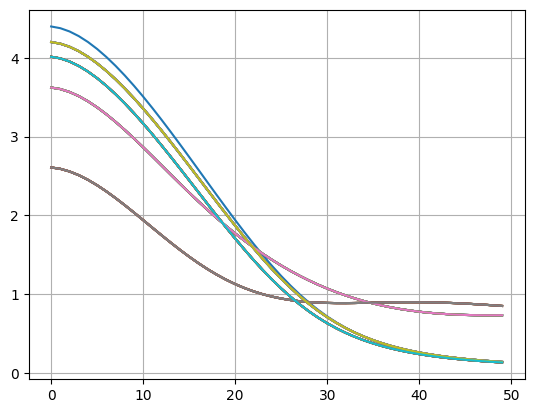

In [17]:
step = 0
for p in range(len(arr_losses)):
    plt.plot(torch.tensor(arr_losses)[:, step])
    if step == num-1:
        step = 0
    step += 1
plt.grid()

In [18]:
len(arr_losses)

50

In [19]:
torch.tensor(arr_losses)[:, 3].shape

torch.Size([50])

In [20]:
torch.tensor(arr_losses)[:, 3]

tensor([2.6081, 2.5905, 2.5572, 2.5100, 2.4509, 2.3816, 2.3037, 2.2190, 2.1290,
        2.0353, 1.9394, 1.8427, 1.7466, 1.6523, 1.5612, 1.4741, 1.3921, 1.3158,
        1.2458, 1.1825, 1.1260, 1.0764, 1.0336, 0.9973, 0.9671, 0.9427, 0.9234,
        0.9087, 0.8981, 0.8910, 0.8868, 0.8849, 0.8848, 0.8859, 0.8878, 0.8901,
        0.8924, 0.8944, 0.8958, 0.8963, 0.8960, 0.8945, 0.8921, 0.8885, 0.8839,
        0.8783, 0.8718, 0.8646, 0.8568, 0.8485])

In [21]:
loss

tensor(0.3960, grad_fn=<NegBackward0>)

In [22]:
torch.tensor(arr_losses)[-1]

tensor([0.1331, 0.1303, 0.7308, 0.8485, 0.1374])

In [23]:
torch.tensor(arr_losses)[-1].mean()

tensor(0.3960)